In [211]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [212]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [308]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

df01 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2",])].drop_duplicates(subset="q45_clé")#.merge(list_affil, on = ["q45_clé", "q44_ufr_labo"], how = "left") #"H5X6-KL2Z",'PS8W-TJ9P'
df01

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5,hc_label,hc_methodo_9,hc_methodo_8,hc_methodo_6,hc_field_8,hc_field_6
0,1,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,NaN,NaN,NaN,NaN,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données,NaN,NaN
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",Humanités,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données,Humanités,Humanités
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Psychologie,Données d'entretiens avec excel,Données d'entretien avec excel,Données d'entretien avec excel,Psychologie,Psychologie
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel",Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Psychologie,Psychologie
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Questions économiques,Analyse de données textuelles avec excel,Analyse de données textuelles avec excel,Analyse de données textuelles avec excel,"Individus, normes, sociétés","Individus, normes, sociétés"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel",Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Psychologie,Psychologie
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,"Individus, normes, sociétés","Individus, normes, sociétés"
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances,Données statistiques avec R,Données statistiques avec R,Analyse de données avec R,"Individus, normes, sociétés","Individus, normes, sociétés"
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,Collectes et analyses de traces numériques,"Données du web, Données multimédia, Données st...",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",MIASSH,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,MIASSH,MIASSH


In [309]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [310]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [311]:
gb_data, df_exp = split_multiple_choices(df01, column='q24_research_fields', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df01, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [312]:
df_rf = df_exp[["q45_clé", 'q24_research_fields']].copy()
df_rf.loc[df_rf.q24_research_fields.isna(), "q24_research_fields"] = "Aucun sous-domaine"

df_rf["value"] = "Oui"
df_rf["question"] = 'q24_research_fields'

df_rf["nb"] = df_rf.groupby(["q24_research_fields"])["q45_clé"].transform("count")
#df_rf2 = df_rf.loc[df_rf.nb>0]
df_rf["q24_research_fields"] = df_rf.apply(lambda row: row.q24_research_fields.split(" ")[0], 1) # lower sentence
df_rf["value_int"] = 1

In [313]:
def create_term_term_matrix(data, what, list_columns, value, fill_value=0):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=fill_value)
    
    #term_term = np.dot(table, table.T) # multiplication de la transposé de
    return table

In [314]:
table = create_term_term_matrix(data = df_rf,  what ="q45_clé", list_columns=["q24_research_fields"], value="value", fill_value="Non")
table2 = create_term_term_matrix(data = df_rf,  what ="q45_clé", list_columns=["q24_research_fields"], value="value_int", fill_value=0)


/tmp/ipykernel_2798/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7f986017f600> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,
/tmp/ipykernel_2798/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7f986017f600> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


In [315]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [316]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [317]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [318]:
for col in table.columns:
    print(col)
    table[col] = table.apply(lambda row: f'{col}_{str(row[col])}', 1) # lower sentence
table

LS4
LS5
LS6
LS7
LS8
LS9
PE1
PE10
PE11
PE5
PE6
PE7
PE8
PE9
SH1
SH2
SH3
SH4
SH5
SH6
SH7
SH8


q24_research_fields,LS4,LS5,LS6,LS7,LS8,LS9,PE1,PE10,PE11,PE5,...,PE8,PE9,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8
q45_clé,,,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
2JQN-P9PA,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
2QNC-8AAQ,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Oui,SH6_Non,SH7_Oui,SH8_Non
2Y89-7BR9,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non
32TW-JLY5,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Oui,PE10_Non,PE11_Oui,PE5_Non,...,PE8_Oui,PE9_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Oui
YTMC-B4DP,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
ZB5S-ABHN,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE8_Non,PE9_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non


## Sélection des données de l'analyse en composante multiple

In [321]:
# Sélection variables actives (utilisées pour construire les facteurs) et les variables illustratives
var_active = [var for var in table.columns if len(df_rf.loc[df_rf.q24_research_fields==var])>9]
var_illust = [var for var in table.columns if len(df_rf.loc[df_rf.q24_research_fields==var])<=9]
var_illust = var_illust + ['label_recherche_1','hc_label','hc_methodo_6','hc_field_8',"hc_field_6"]

# Individus actifs et supplémentaires
table3 = table2[var_active].copy()

ind_supp =[x for x in table3.loc[table3.sum(axis=1)==0].index] + ['PS8W-TJ9P']
ind_actifs =[x for x in table3.loc[table3.sum(axis=1)!=0].index if x != 'PS8W-TJ9P']
ind_supp

['H5X6-KL2Z', 'M5L8-UM9F', 'PS8W-TJ9P']

In [341]:
df_os = table.merge(df0[["q45_clé", 'label_recherche_1','hc_label','hc_methodo_6','hc_field_8',"hc_field_6"]].set_index("q45_clé"), on = None, left_index= True, right_index=True, how="left")
df_os.loc[df_os.index.isin(ind_supp)]
for x in ind_supp:
    if x in ind_actifs:
        print(x)

In [342]:

#récupération des variables actives
DActives = df_os[var_active].loc[df_os.index.isin(ind_actifs)].copy()
#print(DActives)
Dillustratives =  df_os[var_illust].loc[df_os.index.isin(ind_actifs)].copy()
#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]
X

9
9 116


,PE6_Non,PE6_Oui,SH1_Non,SH1_Oui,SH2_Non,SH2_Oui,SH3_Non,SH3_Oui,SH4_Non,SH4_Oui,SH5_Non,SH5_Oui,SH6_Non,SH6_Oui,SH7_Non,SH7_Oui,SH8_Non,SH8_Oui
q45_clé,,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,1,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2JQN-P9PA,1,0,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2QNC-8AAQ,1,0,0,1,1,0,0,1,1,0,0,1,1,0,0,1,1,0
2Y89-7BR9,1,0,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0
32TW-JLY5,0,1,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,1,0,0,1,1,0,0,1,1,0,1,0,1,0,1,0,0,1
YTMC-B4DP,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0,1,0
ZB5S-ABHN,1,0,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0


In [343]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)


['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[2.14070489e-01, 2.14070489e+01, 2.14070489e+01],
       [1.74892714e-01, 1.74892714e+01, 3.88963203e+01],
       [1.20823513e-01, 1.20823513e+01, 5.09786716e+01],
       [1.12372812e-01, 1.12372812e+01, 6.22159528e+01],
       [1.00417666e-01, 1.00417666e+01, 7.22577194e+01],
       [8.91998183e-02, 8.91998183e+00, 8.11777013e+01],
       [7.74443015e-02, 7.74443015e+00, 8.89221314e+01],
       [6.72502509e-02, 6.72502509e+00, 9.56471565e+01],
       [4.35284351e-02, 4.35284351e+00, 1.00000000e+02]])

In [344]:
#nombre max de facteurs
if M > p:
    Hmax = M - p
else:
    Hmax = p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

18 9


,Val_P,%,Cumul %
1,0.214070,21.407049,21.407049
2,0.174893,17.489271,38.896320
3,0.120824,12.082351,50.978672
4,0.112373,11.237281,62.215953
5,0.100418,10.041767,72.257719
6,0.089200,8.919982,81.177701
7,0.077444,7.744430,88.922131
8,0.067250,6.725025,95.647156
9,0.043528,4.352844,100.000000


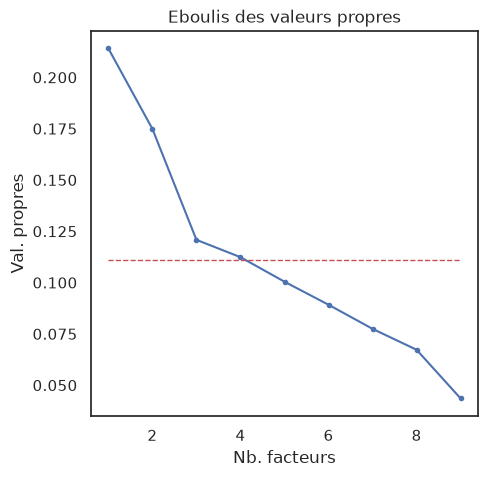

In [345]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

## Correction de Benzecri

In [346]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.21407049 0.17489271 0.12082351 0.11237281]
[1.34164268e-02 5.14868001e-03 1.19387358e-04 2.01473500e-06]
0.01868650894221271


In [347]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage

eigen_val_benz = pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1))
eigen_val_benz

,Val.P,%,Cumul %
1,0.013416,71.797396,71.797396
2,0.005149,27.552926,99.350322
3,0.000119,0.638896,99.989218
4,0.000002,0.010782,100.000000


In [348]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
eigen_val_greenacre = pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1))
print(eigen_val_greenacre)

0.02585671963808301
      Val.P         %   Cumul %
1  0.013416  0.518876  0.518876
2  0.005149  0.199123  0.717999
3  0.000119  0.004617  0.722617
4  0.000002  0.000078  0.722694


In [349]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

         Coord.F1  Coord.F2
PE6_Non  0.126392  0.162206
PE6_Oui -0.736045 -0.944613
SH1_Non -0.282066 -0.016395
SH1_Oui  1.205193  0.070053
SH2_Non -0.258978  0.008957
SH2_Oui  1.409994 -0.048766
SH3_Non -0.664631 -0.377887
SH3_Oui  0.521479  0.296496
SH4_Non  0.339247 -0.077257
SH4_Oui -0.669796  0.152532
SH5_Non  0.169551 -0.273292
SH5_Oui -0.586907  0.946010
SH6_Non  0.047627 -0.403401
SH6_Oui -0.182569  1.546371
SH7_Non -0.291138 -0.128829
SH7_Oui  1.177211  0.520919
SH8_Non  0.220433 -0.402524
SH8_Oui -0.470655  0.859443


In [350]:
df_rows = acm.row_topandas()


df_cols = acm.col_topandas()
dict_lab_short = {}
for lab in df_cols.index:
    lab_split = lab.split("_")
    dict_lab_short[lab] = "_".join(lab_split[1:])

df_cols["label"] = df_cols.index.map(dict_lab_short.get)
df_cols[["label",'col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)



,label,col_contrib_dim1,col_contrib_dim2,col_cos2_dim1,col_cos2_dim2
SH2_SH2_Oui,SH2_Oui,16.012146,0.023444,0.365158,0.000437
SH1_SH1_Oui,SH1_Oui,14.298105,0.059130,0.339944,0.001149
SH7_SH7_Oui,SH7_Oui,14.261952,3.418191,0.342731,0.067110
SH3_SH3_Non,SH3_Non,10.080305,3.988611,0.346591,0.112042
SH3_SH3_Oui,SH3_Oui,7.909163,3.129526,0.346591,0.112042
SH4_SH4_Oui,SH4_Oui,7.828739,0.496953,0.227226,0.011784
PE6_PE6_Oui,PE6_Oui,4.120979,8.307770,0.093030,0.153222
SH5_SH5_Oui,SH5_Oui,4.007330,12.743617,0.099511,0.258537
SH4_SH4_Non,SH4_Non,3.965206,0.251703,0.227226,0.011784
SH8_SH8_Oui,SH8_Oui,3.667320,14.968004,0.103748,0.345947


## Projection des variables illustratives

Calcul des coordonnées des variables illustratives et coefficient de corrélation

## Coefficient de corrélation avec facteur des variables illustratives

In [351]:
for factor in range(len(eigen_val_greenacre)):
    Dillustratives[f"F{factor+1}"] = acm.row_coord_[:,factor:factor+1]
Dillustratives

,LS4,LS5,LS6,LS7,LS8,LS9,PE1,PE10,PE11,PE5,...,PE9,label_recherche_1,hc_label,hc_methodo_6,hc_field_8,hc_field_6,F1,F2,F3,F4
q45_clé,,,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,Psychologie,MIASSH,Analyse de données mixtes,MIASSH,MIASSH,-0.591975,-0.633786,0.002522,-0.132660
2JQN-P9PA,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,Psychologie,Psychologie,Analyse de données avec R,Psychologie,Psychologie,-0.384863,-0.339717,0.122726,-0.401293
2QNC-8AAQ,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,"Individus, normes, société",Dynamiques spaciales,Analyses manuelles des données,"Individus, normes, sociétés","Individus, normes, sociétés",0.670420,0.297958,-0.286101,-0.143902
2Y89-7BR9,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,Psychologie,"Langues, langage et communication",Données d'entretien avec excel,Psychologie,Psychologie,-0.566525,-0.015764,-0.227553,-0.551021
32TW-JLY5,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Oui,PE10_Non,PE11_Oui,PE5_Non,...,PE9_Non,Sciences informatiques,MIASSH,Analyse de données mixtes,MIASSH,MIASSH,-0.349656,-0.694838,-0.036112,0.407026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,Histoires sociales du politique,Questions économiques,Analyse de données mixtes,"Individus, normes, sociétés","Individus, normes, sociétés",0.333498,0.136664,-0.374464,0.321565
YTMC-B4DP,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,Psychologie sociale,Psychologie,Analyse de données avec R,Psychologie,Psychologie,-0.100021,-0.160542,0.275438,-0.532544
ZB5S-ABHN,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,...,PE9_Non,Psychologie,"Langues, langage et communication",Analyse de données avec R,Psychologie,Psychologie,-0.566525,-0.015764,-0.227553,-0.551021


In [352]:



i=-1
for n, var in enumerate(var_illust):
    i+=1
    # définition des coordonnées
    GBar = pd.pivot_table(Dillustratives,values=[f"F{f+1}" for f in range(len(eigen_val_greenacre))],index=var,aggfunc='mean') # moyenne des coordonnées 
    Gv0 = GBar.values/np.sqrt(acm.eig_[0,0:1])
    Gv0 = pd.DataFrame(Gv0,index=GBar.index,columns=GBar.columns)
    Gv0["variable"]=var

    

    n_g = pd.pivot_table(Dillustratives,values=['F1'],index=var,aggfunc='count') #effectif par 
    n = np.sum(n_g.F1)
    dict_corr = {"variable":var}

    for f in range(len(eigen_val_greenacre)):
        dict_corr[f"F{f+1}"] = np.sum((n_g.F1/n)*(GBar[f"F{f+1}"]**2))/acm.eig_[0][0]
        


    df_corr0 = pd.DataFrame.from_dict([dict_corr])
    df_corr0 = df_corr0.set_index("variable")

    if i == 0:
        Gv = Gv0.copy()
        df_corr = df_corr0.copy()
    else:
        Gv = pd.concat([Gv,Gv0])
        df_corr = pd.concat([df_corr, df_corr0])


## Projection des individus supplémentaires

In [439]:
DSupp = df_os[var_active].loc[df_os.index.isin(ind_supp)].copy()

DSupp

,LS4,LS5,LS6,LS7,LS8,LS9,PE1,PE10,PE11,PE5,PE7,PE8,PE9,label_recherche_1,hc_label,hc_methodo_6,hc_field_8,hc_field_6
q45_clé,,,,,,,,,,,,,,,,,,
H5X6-KL2Z,LS4_Non,LS5_Non,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Oui,PE7_Non,PE8_Non,PE9_Non,NaN,NaN,Analyse de données mixtes,NaN,NaN
M5L8-UM9F,LS4_Oui,LS5_Oui,LS6_Non,LS7_Non,LS8_Non,LS9_Non,PE1_Non,PE10_Non,PE11_Non,PE5_Non,PE7_Non,PE8_Non,PE9_Non,Psychologie,NaN,Analyse de données avec R,NaN,NaN
PS8W-TJ9P,LS4_Oui,LS5_Non,LS6_Oui,LS7_Oui,LS8_Oui,LS9_Oui,PE1_Non,PE10_Oui,PE11_Non,PE5_Non,PE7_Oui,PE8_Oui,PE9_Oui,NaN,NaN,Analyses manuelles des données,NaN,NaN


In [436]:
#vecteur pour individu supplémentaire

for ind in DSupp.index :
    XSupp = np.zeros(M)
    XSupp
    
    for v in DSupp.loc[ind].values:
        XSupp[np.where(X.columns==v)] = 1
    
    XSupp = XSupp / p #p = nombre de variable
    print(XSupp)
    
    #projection
    coord_supp = np.dot(np.reshape(XSupp,(1,M)),acm.col_coord_[:,:4])
    coord_supp = coord_supp / np.sqrt(acm.eig_[0][:4])
    print(coord_supp)
    
    for f in range(len(eigen_val_greenacre)):
        DSupp.loc[ind, f"F{f+1}"] = coord_supp[:,f]
DSupp

[0.11111111 0.         0.11111111 0.         0.11111111 0.
 0.11111111 0.         0.11111111 0.         0.11111111 0.
 0.11111111 0.         0.11111111 0.         0.11111111 0.        ]
[[-0.14254332 -0.40076937  0.08409177  0.1383926 ]]
[0.11111111 0.         0.11111111 0.         0.11111111 0.
 0.11111111 0.         0.11111111 0.         0.11111111 0.
 0.11111111 0.         0.11111111 0.         0.11111111 0.        ]
[[-0.14254332 -0.40076937  0.08409177  0.1383926 ]]
[0.11111111 0.         0.         0.11111111 0.         0.11111111
 0.         0.11111111 0.11111111 0.         0.         0.11111111
 0.         0.11111111 0.         0.11111111 0.         0.11111111]
[[ 0.84997646  1.13594199 -0.60308436  0.17877149]]


,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8,F1,F2,F3,F4
q45_clé,,,,,,,,,,,,,
H5X6-KL2Z,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,-0.142543,-0.400769,0.084092,0.138393
M5L8-UM9F,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,-0.142543,-0.400769,0.084092,0.138393
PS8W-TJ9P,PE6_Non,SH1_Oui,SH2_Oui,SH3_Oui,SH4_Non,SH5_Oui,SH6_Oui,SH7_Oui,SH8_Oui,0.849976,1.135942,-0.603084,0.178771


# Graphique des individus

In [363]:
import matplotlib.cm as cm
import matplotlib as mpl




In [364]:
df_corr

,F1,F2,F3,F4
variable,,,,
LS4,3.851148e-35,4.279053e-36,2.166271e-33,2.842254e-32
LS5,1.176259e-02,9.057372e-03,5.578636e-03,1.212414e-02
LS6,3.851148e-35,4.279053e-36,2.166271e-33,2.842254e-32
LS7,2.314215e-04,1.411055e-03,1.588422e-02,2.109365e-02
LS8,3.851148e-35,4.279053e-36,2.166271e-33,2.842254e-32
LS9,3.851148e-35,4.279053e-36,2.166271e-33,2.842254e-32
PE1,2.932318e-02,1.096518e-02,1.134087e-03,1.419359e-03
PE10,1.792692e-03,2.114193e-03,8.668586e-03,1.249984e-03
PE11,4.966230e-03,1.961156e-02,5.297250e-05,6.729608e-03


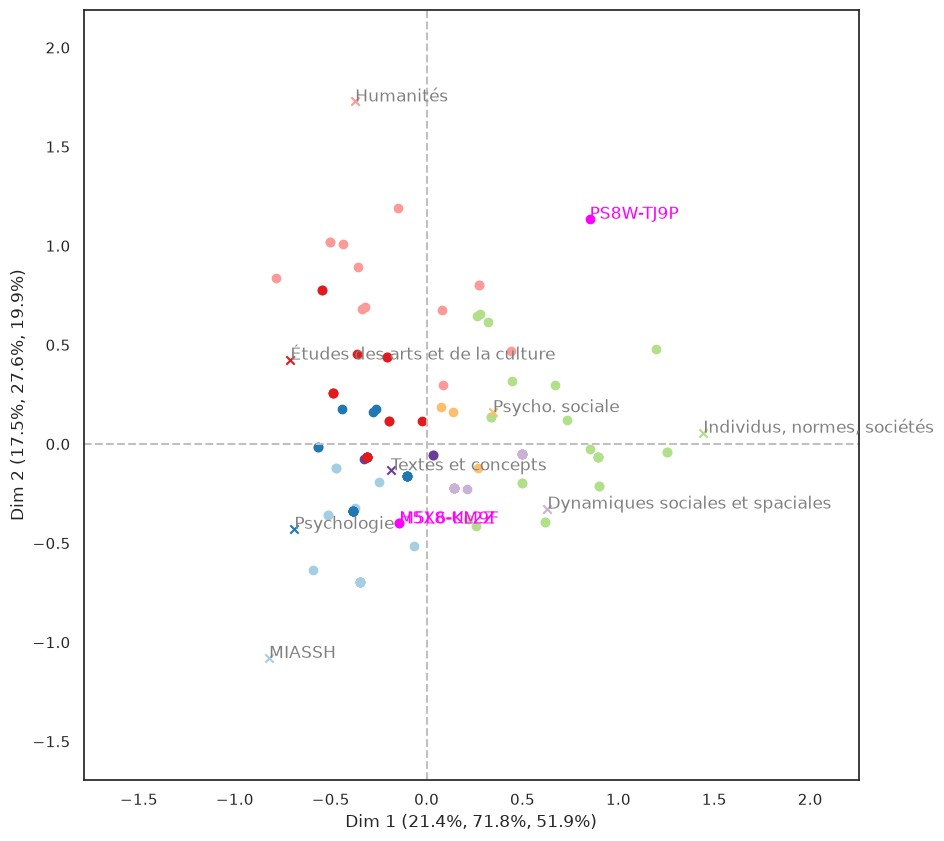

In [365]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 2
min_abs = np.min(df_rows[f"row_coord_dim{dim_x}"])-1
max_abs = np.max(df_rows[f"row_coord_dim{dim_x}"])+1
min_ord = np.min(df_rows[f"row_coord_dim{dim_y}"])-1
max_ord = np.max(df_rows[f"row_coord_dim{dim_y}"])+1


show_ind_supp = True
show_var_illustratives = True
var_illustratives = ["hc_field_8"]


    

cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 10))

dict_mod_id = {}
for n, mod in enumerate(Dillustratives[var_illustratives[0]].unique()):
    dict_mod_id[mod] = n

Dillustratives["id_label"] = Dillustratives[var_illustratives[0]].map(dict_mod_id.get)
c_label =[colors_map[i] for i in Dillustratives.id_label]


# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

#ax[0].subtitle("Représentation des points-modalités")
for i in range(df_rows.shape[0]):
    ax.scatter(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1],color=c_label[i])

if show_ind_supp == True:
    for i in DSupp.index:
    #individu supplémentaire
        x = DSupp.loc[i].iloc[(dim_x-1)+p]
        y = DSupp.loc[i].iloc[(dim_y-1)+p]
        #ax.scatter(DSupp)
        ax.scatter(x,y,color='magenta')
        ax.text(x,y,i,color='magenta',fontsize=12)

if show_var_illustratives == True:
    for var in var_illustratives:
        Gv1 = Gv.loc[Gv.variable == var]
        for i in Gv1.index:
            x = Gv1.loc[i].iloc[dim_x-1]
            y = Gv1.loc[i].iloc[dim_y-1]
            ax.scatter(x,y,color=colors_map[dict_mod_id[i]], marker="x")
            ax.text(x,y,i,color="grey")


else:
    pass




plt.show()

## Graphique des variables

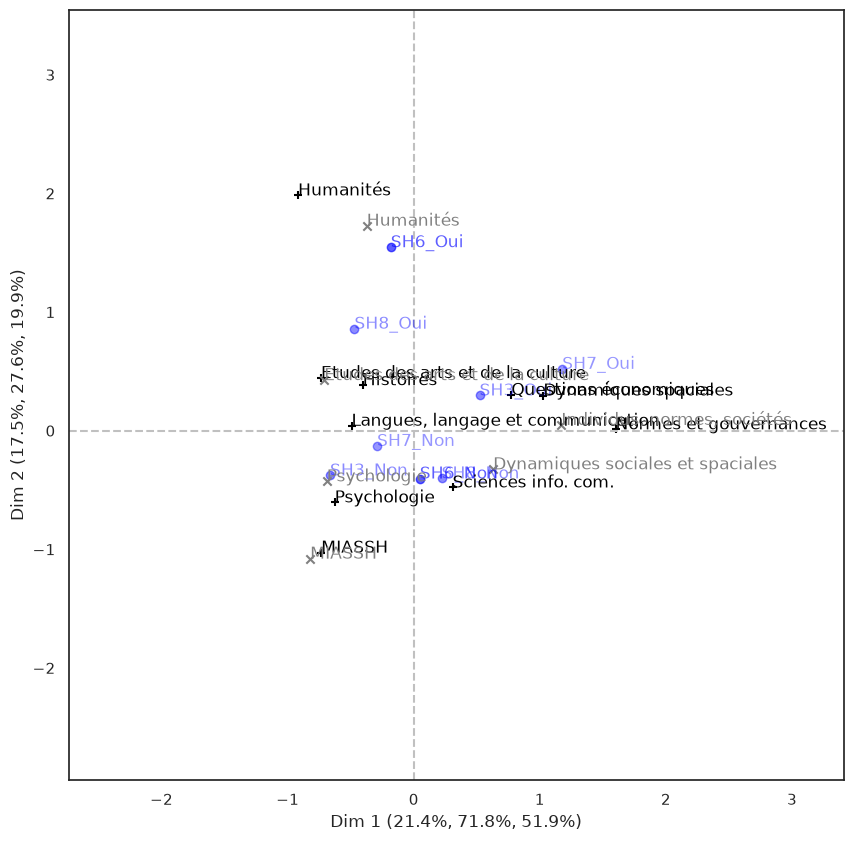

In [366]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 2
min_abs = np.min(df_cols[f"col_coord_dim{dim_x}"])-2
max_abs = np.max(df_cols[f"col_coord_dim{dim_x}"])+2
min_ord = np.min(df_cols[f"col_coord_dim{dim_y}"])-2
max_ord = np.max(df_cols[f"col_coord_dim{dim_y}"])+2

show_var_illustratives = True
var_illustratives = ["hc_label","hc_field_6"]


cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 10))


dict_mod_id = {}
for n, mod in enumerate(Dillustratives[var_illustratives[0]].unique()):
    dict_mod_id[mod] = n

Dillustratives["id_label"] = Dillustratives[var_illustratives[0]].map(dict_mod_id.get)
c_label =[colors_map[i] for i in Dillustratives.id_label]

# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

df_cols["cos_cumsum"] = df_cols[f"col_cos2_dim{dim_x}"]+df_cols[f"col_cos2_dim{dim_y}"]
df_cols1 = df_cols.loc[df_cols["cos_cumsum"]>0.4]

#ax[0].subtitle("Représentation des points-modalités")
for i in range(df_cols1.shape[0]):
    ax.scatter(df_cols1[f"col_coord_dim{dim_x}"].iloc[i],df_cols1[f"col_coord_dim{dim_y}"].iloc[i],color="blue", alpha=df_cols1["cos_cumsum"].iloc[i])
    ax.text(df_cols1[f"col_coord_dim{dim_x}"].iloc[i],df_cols1[f"col_coord_dim{dim_y}"].iloc[i],df_cols1.label.iloc[i],color="blue",  alpha=df_cols1["cos_cumsum"].iloc[i])

if var_illustratives != False:
    couleur = ["black", "grey"]
    mark = ["+","x"]
    for n, var in enumerate(var_illustratives):
        Gv1 = Gv.loc[Gv.variable == var]
        for i in Gv1.index:
            x = Gv1.loc[i].iloc[dim_x-1]
            y = Gv1.loc[i].iloc[dim_y-1]
            ax.scatter(x,y,color=couleur[n], marker=mark[n])
            ax.text(x,y,i,color=couleur[n])
else:
    pass




plt.show()

In [367]:
import datamapplot

In [368]:
df_coord= pd.DataFrame(acm.row_coord_[:,:2],index=X.index,columns=['F1','F2'])
df_coord['hc_label'] = Dillustratives.hc_field_6

dict_hc_label={}
for n, x in enumerate(df_coord.hc_label.unique()):
    dict_hc_label[x] = n
df_coord["id_hc_label"] = df_coord.hc_label.map(dict_hc_label.get)
lab = [i for n, i in enumerate(df_coord.hc_label)]

data_map = acm.row_coord_[:,:2]
data_map.shape
data_label = np.array(lab, dtype="object")


(<Figure size 1000x1000 with 1 Axes>, <Axes: >)

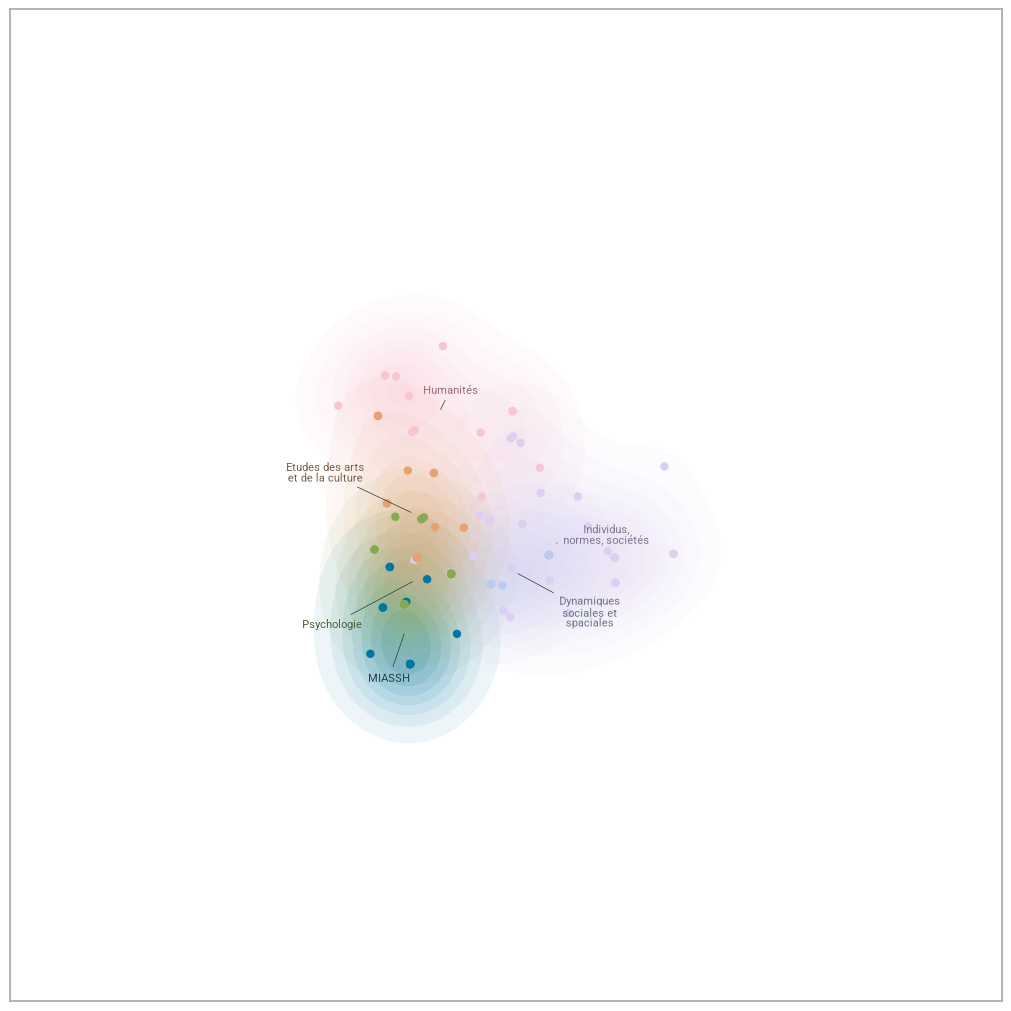

In [369]:
datamapplot.create_plot(data_map, data_label)

In [370]:
print(pd.DataFrame(np.cumsum(acm.col_cos2_[:,:4],axis=1),index=df_cols.index,columns=['Cos2.F1','Cum(Cos2).F2', 'Cum(Cos2).F3', 'Cum(Cos2).F4']))

              Cos2.F1  Cum(Cos2).F2  Cum(Cos2).F3  Cum(Cos2).F4
PE6_PE6_Non  0.093030      0.246252      0.263938      0.346094
PE6_PE6_Oui  0.093030      0.246252      0.263938      0.346094
SH1_SH1_Non  0.339944      0.341093      0.796889      0.798946
SH1_SH1_Oui  0.339944      0.341093      0.796889      0.798946
SH2_SH2_Non  0.365158      0.365595      0.478594      0.487333
SH2_SH2_Oui  0.365158      0.365595      0.478594      0.487333
SH3_SH3_Non  0.346591      0.458633      0.514861      0.553490
SH3_SH3_Oui  0.346591      0.458633      0.514861      0.553490
SH4_SH4_Non  0.227226      0.239010      0.242270      0.833924
SH4_SH4_Oui  0.227226      0.239010      0.242270      0.833924
SH5_SH5_Non  0.099511      0.358048      0.566864      0.602350
SH5_SH5_Oui  0.099511      0.358048      0.566864      0.602350
SH6_SH6_Non  0.008695      0.632503      0.635146      0.639744
SH6_SH6_Oui  0.008695      0.632503      0.635146      0.639744
SH7_SH7_Non  0.342731      0.409841     

In [371]:
acm.col_contrib_[:,[0,2]]

array([[ 0.70764284,  0.23836275],
       [ 4.12097891,  1.38811251],
       [ 3.34636507,  7.94952956],
       [14.29810531, 33.96617174],
       [ 2.94100647,  1.61249337],
       [16.01214633,  8.77913054],
       [10.08030516,  2.89742442],
       [ 7.90916251,  2.27336378],
       [ 3.96520572,  0.10079437],
       [ 7.82873949,  0.19900427],
       [ 1.15767323,  4.30413853],
       [ 4.0073304 , 14.89894105],
       [ 0.09337475,  0.05029023],
       [ 0.35793655,  0.19277921],
       [ 3.52714934,  4.05024023],
       [14.26195166, 16.37705831],
       [ 1.71760579,  0.23034577],
       [ 3.66732047,  0.49181935]])

In [372]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,:4],index=X.columns)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
#structure pour les eta2
cols=len(table[var_active].columns)
eta2 = np.zeros((cols,4))
#pour chaque facteur
for h in range(4):
    #pour chaque variable
    for j in range(cols):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(table[var_active].iloc[:,j])][h]))/100
            #affichage

print(pd.DataFrame(eta2,index=table[var_active].columns[:],columns=['F1','F2','F3','F4']))



                 0          1          2          3
PE6_Non   0.707643   1.426587   0.238363   1.190479
PE6_Oui   4.120979   8.307770   1.388113   6.932790
SH1_Non   3.346365   0.013839   7.949530   0.038567
SH1_Oui  14.298105   0.059130  33.966172   0.164785
SH2_Non   2.941006   0.004306   1.612493   0.134073
SH2_Oui  16.012146   0.023444   8.779131   0.729953
SH3_Non  10.080305   3.988611   2.897424   2.140269
SH3_Oui   7.909163   3.129526   2.273364   1.679288
SH4_Non   3.965206   0.251703   0.100794  19.668457
SH4_Oui   7.828739   0.496953   0.199004  38.832595
SH5_Non   1.157673   3.681489   4.304139   0.786438
SH5_Oui   4.007330  12.743617  14.898941   2.722287
SH6_Non   0.093375   8.199546   0.050290   0.094058
SH6_Oui   0.357937  31.431594   0.192779   0.360555
SH7_Non   3.527149   0.845359   4.050240   0.038892
SH7_Oui  14.261952   3.418191  16.377058   0.157258
SH8_Non   1.717606   7.010331   0.230346   7.760194
SH8_Oui   3.667320  14.968004   0.491819  16.569063
            

In [373]:
eta2

array([[9.30298878e-02, 1.53222123e-01, 1.76864810e-02, 8.21551079e-02],
       [3.39944437e-01, 1.14855485e-03, 4.55796206e-01, 2.05660645e-03],
       [3.65157962e-01, 4.36796518e-04, 1.12999726e-01, 8.73837569e-03],
       [3.46591273e-01, 1.12041925e-01, 5.62277516e-02, 3.86292861e-02],
       [2.27226206e-01, 1.17841061e-02, 3.26004533e-03, 5.91653498e-01],
       [9.95107368e-02, 2.58536823e-01, 2.08816518e-01, 3.54856767e-02],
       [8.69511893e-03, 6.23807797e-01, 2.64316526e-03, 4.59775645e-03],
       [3.42730940e-01, 6.71097484e-02, 2.22128817e-01, 1.98377267e-03],
       [1.03747842e-01, 3.45946551e-01, 7.85290748e-03, 2.46055229e-01]])

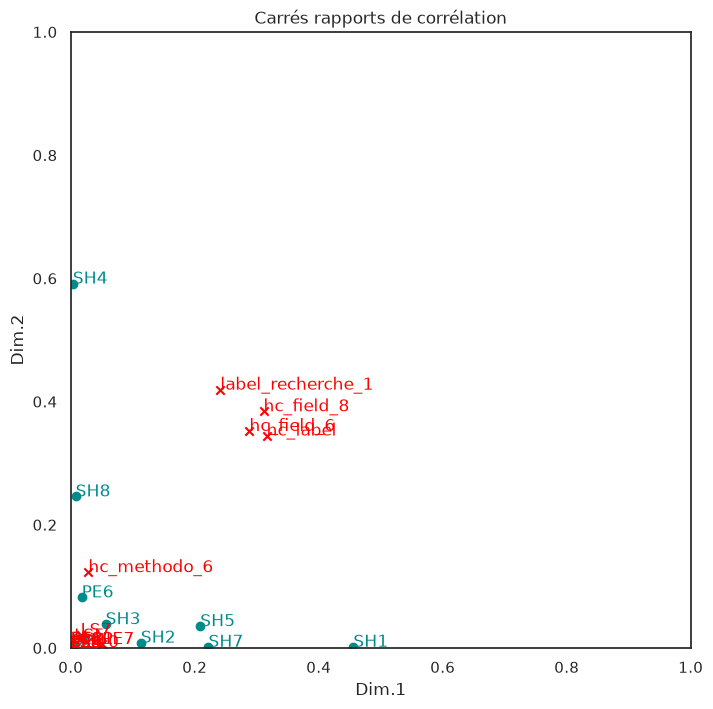

In [374]:
fix,ax = plt.subplots(figsize=(8,8))

dim_x = 3
dim_y = 4

ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(cols):
    ax.scatter(eta2[i,dim_x-1],eta2[i,dim_y-1],color='darkcyan')
    ax.text(eta2[i,dim_x-1],eta2[i,dim_y-1],df_os[var_active].columns[i],color='darkcyan')

corr_ill = np.array(df_corr)
for n, i in enumerate(df_corr.index):
    x= corr_ill[n,dim_x-1]
    y= corr_ill[n,dim_y-1]
    ax.scatter(x,y, color='red', marker="x")
    ax.text(x,y, i,color='red')
plt.show()

In [375]:
print(df0.auto_lab_research_cluster.value_counts().to_markdown())

| auto_lab_research_cluster                                                                                                                            |   count |
|:-----------------------------------------------------------------------------------------------------------------------------------------------------|--------:|
| ["SH4 L'esprit humain et sa complexité", 'SH8 Études des cultures et des arts', 'SH5 Textes et concepts']                                            |      19 |
| ["SH4 L'esprit humain et sa complexité", 'LS5 Neurosciences et troubles du système nerveux', 'SH5 Textes et concepts']                               |      18 |
| ['SH2 Institutions, gouvernance et systèmes juridiques', 'SH1 Individus, marchés et organisations', 'SH7 Mobilité humaine, environnement et espace'] |      16 |
| ['SH5 Textes et concepts', 'SH8 Études des cultures et des arts', "SH6 L'étude du passé humain"]                                                     |      13 |
| ['SH8 Études des cul

In [376]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

In [377]:
# Extract the row coordinates (numerical representation of your rows)
acm.row_coord_



array([[-5.91975441e-01, -6.33785678e-01,  2.52229040e-03, ...,
        -1.16660919e-04, -2.63761384e-01, -2.48198197e-01],
       [-3.84862960e-01, -3.39717317e-01,  1.22726149e-01, ...,
         1.88153989e-01, -4.16594449e-02, -1.54903192e-01],
       [ 6.70420312e-01,  2.97958268e-01, -2.86100666e-01, ...,
         6.30785014e-03,  1.92925996e-01, -2.92938321e-01],
       ...,
       [-5.66524973e-01, -1.57636529e-02, -2.27552968e-01, ...,
         2.98487548e-01,  2.29024044e-01,  6.03575267e-02],
       [-3.49655797e-01, -6.94837732e-01, -3.61120857e-02, ...,
         2.92285231e-02, -2.73135784e-01,  3.69388514e-02],
       [-3.57418532e-01,  8.95293591e-01,  1.62612929e-01, ...,
        -5.74333184e-02, -1.00437640e-01, -3.51941974e-01]],
      shape=(116, 9))

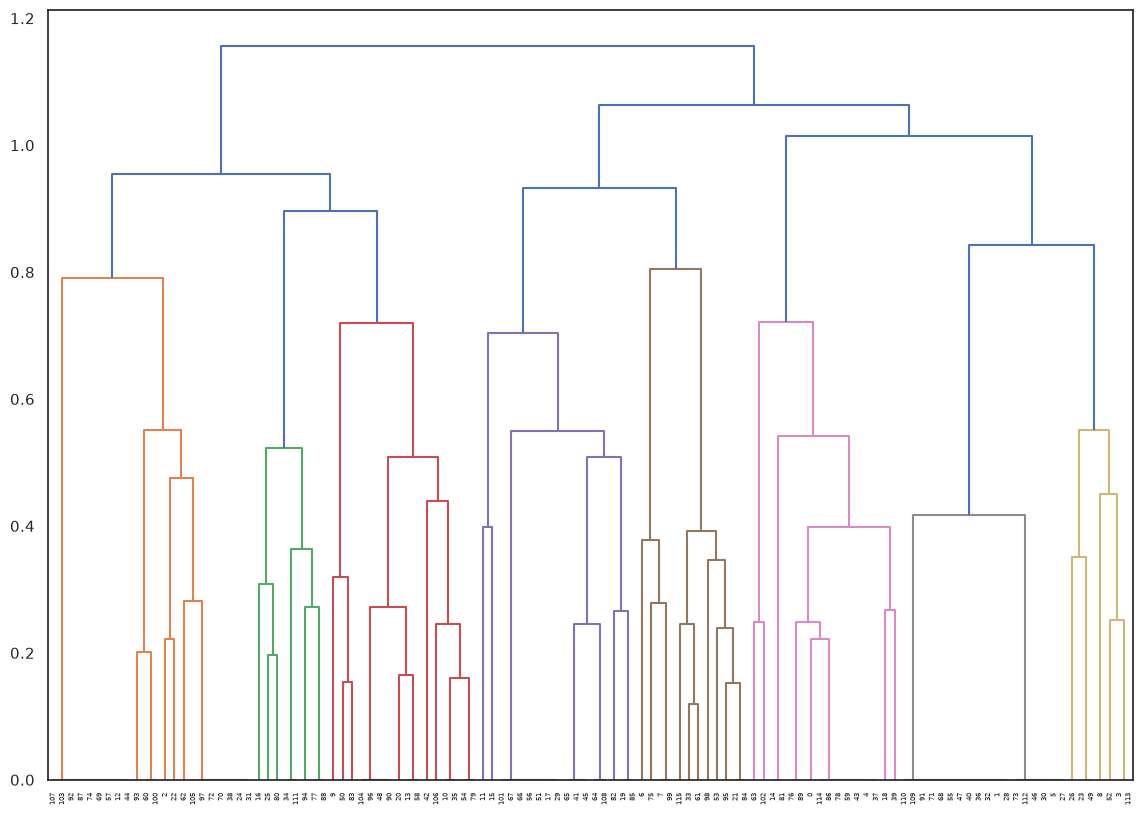

In [378]:


x = [4, 5, 10, 4, 3, 11, 14 , 6, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]

data = list(zip(x, y))

linkage_data = linkage(acm.row_coord_, method='average', metric='cosine')
dendrogram(linkage_data)

plt.show() 

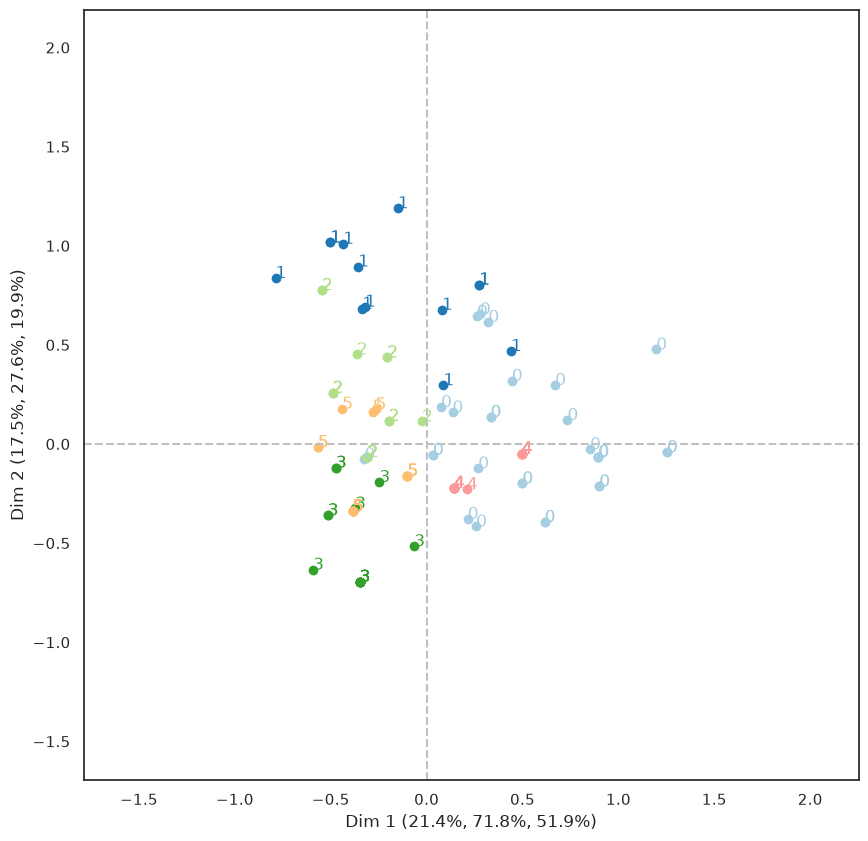

In [379]:
#représentation dans le plan
from sklearn.cluster import AgglomerativeClustering

x = acm.row_coord_[:,0]
y = acm.row_coord_[:,1]

data = list(zip(x, y))

hierarchical_cluster = AgglomerativeClustering(n_clusters=6, metric="cosine",linkage="average")
labels = hierarchical_cluster.fit_predict(acm.row_coord_[:,:5])
kmeans = KMeans(n_clusters=8, random_state=42, n_init='auto')
labels_k = kmeans.fit_predict(acm.row_coord_[:,:5])


fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 2
min_abs = np.min(df_rows[f"row_coord_dim{dim_x}"])-1
max_abs = np.max(df_rows[f"row_coord_dim{dim_x}"])+1
min_ord = np.min(df_rows[f"row_coord_dim{dim_y}"])-1
max_ord = np.max(df_rows[f"row_coord_dim{dim_y}"])+1



cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 11))

c_label =[colors_map[i] for i in labels]

# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

#ax[0].subtitle("Représentation des points-modalités")
for i in range(len(c_label)):
    
    if labels[i]<10:
        ax.scatter(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1],color=c_label[i])
        ax.text(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1], labels[i], color=c_label[i])





plt.show()

In [380]:

hierarchical_cluster = AgglomerativeClustering(n_clusters=6, metric="cosine",linkage="average")
DActives["hierarcical_clust_all"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:5])
#DActives["hierarcical_clust_all_9"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:])

In [381]:

d = DActives.loc[DActives.hierarcical_clust_all==6]
print(len(d))
for x in d.columns[:-2]:
    print(d[x].loc[d[x].str.contains("Oui")].value_counts())
d

0
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)


,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8,kmeans,hierarcical_clust_all
q45_clé,,,,,,,,,,,


In [445]:
hierarchical_cluster = AgglomerativeClustering(n_clusters=10, metric="cosine",linkage="average")
DActives["hierarcical_clust_all"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:])
dict_label_hc_all ={0:"MIASSH",
                1:"Normes et gouvernances",
                2:"Etudes des arts et de la culture",
                3:"Psychologie",
                4:"Dynamiques spaciales",
                5:"Langues, langage et communication",
                6:"Questions économiques",
                7:"Humanités",
                8:"Histoires",
                9:"Sciences info. com.",
                   }


DActives["hc_label"]=DActives.hierarcical_clust_all.map(dict_label_hc_4d_6.get)

hierarchical_cluster = AgglomerativeClustering(n_clusters=8, metric="cosine",linkage="average")
DActives["hierarcical_clust_8"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:5])
dict_label_hc_4d_8 ={0:"Individus, normes, sociétés",
                1:"Humanités",
                2:"Études des arts et de la culture",
                3:"MIASSH",
                4:"Dynamiques sociales et spaciales",
                5:"Psychologie",
                6:"Textes et concepts",
                7:"Psycho. sociale"
                   }



DActives["hc_field_8"]=DActives.hierarcical_clust_8.map(dict_label_hc_4d_6.get)

In [446]:
hierarchical_cluster = AgglomerativeClustering(n_clusters=6, metric="cosine",linkage="average")
DActives["hierarcical_clust_6"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:5])
dict_label_hc_4d_6 ={0:"Individus, normes, sociétés",
                1:"Humanités",
                2:"Etudes des arts et de la culture",
                3:"MIASSH",
                4:"Dynamiques sociales et spaciales",
                5:"Psychologie"
                   }

DActives["hc_field_6"]=DActives.hierarcical_clust_6.map(dict_label_hc_4d_6.get)

## Assigner les individus supplémentaires à un cluster

In [447]:
medioid = Gv.loc[Gv.variable=="hc_field_6"].drop(columns=["variable"])
medioid

,F1,F2,F3,F4
Dynamiques sociales et spaciales,0.629991,-0.326136,0.876722,0.069784
Etudes des arts et de la culture,-0.710203,0.425799,-0.150063,0.837023
Humanités,-0.372611,1.727693,0.405437,-0.148926
"Individus, normes, sociétés",1.170084,0.048284,-0.723424,-0.054106
MIASSH,-0.821468,-1.078927,-0.146501,0.640861
Psychologie,-0.689685,-0.428030,0.279409,-0.969845


In [448]:
from scipy.spatial.distance import cdist

In [437]:
for cluster in ["hc_field_8", "hc_field_6", "hc_label"]:
    medioid = Gv.loc[Gv.variable==cluster].drop(columns=["variable"])
    distances = cdist(DSupp.iloc[:,9:13], medioid.values, metric="cosine")
    
    # Index of the closest centroid for each new row
    nearest_cluster_idx = distances.argmin(axis=1)
    assigned_clusters = medioid.index[nearest_cluster_idx]
    #DSupp.loc[ind, cluster]= assigned_clusters[0]
    DSupp[cluster] = medioid.index[nearest_cluster_idx]


In [442]:
DSupp.loc[DSupp.index=="M5L8-UM9F", "hc_field_6"]="Psychologie"
DSupp.loc[DSupp.index=="M5L8-UM9F", "hc_field_8"]="Psychologie"
DSupp.loc[DSupp.index=="M5L8-UM9F", "hc_label"]="Psychologie"
DSupp

,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8,F1,F2,F3,F4,hc_field_8,hc_field_6,hc_label
q45_clé,,,,,,,,,,,,,,,,
H5X6-KL2Z,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,-0.142543,-0.400769,0.084092,0.138393,MIASSH,MIASSH,MIASSH
M5L8-UM9F,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,-0.142543,-0.400769,0.084092,0.138393,Psychologie,Psychologie,Psychologie
PS8W-TJ9P,PE6_Non,SH1_Oui,SH2_Oui,SH3_Oui,SH4_Non,SH5_Oui,SH6_Oui,SH7_Oui,SH8_Oui,0.849976,1.135942,-0.603084,0.178771,"Individus, normes, sociétés","Individus, normes, sociétés",Questions économiques


In [450]:
D_newvar = pd.concat([DActives[["hc_field_8","hc_field_6","hc_label"]].reset_index(), DSupp[["hc_field_8","hc_field_6","hc_label"]].reset_index()])
D_newvar

,q45_clé,hc_field_8,hc_field_6,hc_label
0,2DRU-P3AV,MIASSH,MIASSH,"Individus, normes, sociétés"
1,2JQN-P9PA,Psychologie,Psychologie,MIASSH
2,2QNC-8AAQ,"Individus, normes, sociétés","Individus, normes, sociétés",Dynamiques sociales et spaciales
3,2Y89-7BR9,Psychologie,Psychologie,Psychologie
4,32TW-JLY5,MIASSH,MIASSH,"Individus, normes, sociétés"
...,...,...,...,...
114,ZBFK-V8BA,MIASSH,MIASSH,"Individus, normes, sociétés"
115,ZGPH-2FPH,Humanités,Humanités,None
0,H5X6-KL2Z,MIASSH,MIASSH,MIASSH
1,M5L8-UM9F,Psychologie,Psychologie,Psychologie


In [452]:
df02 = df0.drop(columns=["hc_field_8","hc_field_6","hc_label"]).merge(D_newvar, on=["q45_clé"], how = "left")
df02

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5,hc_methodo_9,hc_methodo_8,hc_methodo_6,hc_field_8,hc_field_6,hc_label
0,1,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,NaN,NaN,NaN,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données,"Individus, normes, sociétés","Individus, normes, sociétés",Questions économiques
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données,Humanités,Humanités,None
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Données d'entretiens avec excel,Données d'entretien avec excel,Données d'entretien avec excel,Psychologie,Psychologie,MIASSH
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel",Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Psychologie,Psychologie,MIASSH
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Analyse de données textuelles avec excel,Analyse de données textuelles avec excel,Analyse de données textuelles avec excel,"Individus, normes, sociétés","Individus, normes, sociétés",None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel",Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Psychologie,Psychologie,MIASSH
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Données mixtes,Analyse de données mixtes,Analyse de données mixtes,"Individus, normes, sociétés","Individus, normes, sociétés",Humanités
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Données statistiques avec R,Données statistiques avec R,Analyse de données avec R,"Individus, normes, sociétés","Individus, normes, sociétés",Humanités
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,Collectes et analyses de traces numériques,"Données du web, Données multimédia, Données st...",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",Données mixtes,Analyse de données mixtes,Analyse de données mixtes,MIASSH,MIASSH,"Individus, normes, sociétés"


In [454]:
# on enregistre les nouvelles variables dans le dataframe original
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "w") as file_out:
    df02.to_csv(file_out, sep=",", index= False)

In [151]:
dic_new_var = {'name':"Aire de rechere",
               'label':'hc_field_6',
               'group':'champ de recherche',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.hc_field_6.dtypes,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des champs de recherche (n=6) identifié par une classification hiérarchique ascendante après analyse en composantes multiple"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col1 = pd.concat([df_col,new_variable], ignore_index = True)
df_col1

,name,label,group,personal_data,type,opened_question,type_panda,no_question,question,question_family,comment
0,N°Obs,qno_obs,NaN,False,numérique,False,int64,0.0,NaN,qno,NaN
1,1. so_principles,q1_so_principles,1_connaissance_so,False,ordinal,False,object,1.0,1/ Diriez-vous que vous êtes familier.ère des ...,q1,NaN
2,2. hal_depot,q2_hal_depot,1_connaissance_so,False,ordinal,False,object,2.0,2/ Avez-vous déjà déposé une production scient...,q2,NaN
3,3. octavi_depot,q3_octavi_depot,2_bib_num,False,nominal_multiple,False,object,3.0,3/ Avez-vous des productions déposées sur Octa...,q3,NaN
4,4. open_data,q4_diff_data,3_entrepot,False,nominal_multiple,False,object,4.0,4/ Avez-vous déjà diffusé vos données de reche...,q4,NaN
...,...,...,...,...,...,...,...,...,...,...,...
162,Aire de rechere,hc_label,champ de recherche,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des cha...
163,Données traitées,hc_methodo_9,type de données produites,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des gro...
164,Données traitées,hc_methodo_8,type de données produites,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des gro...
165,Données traitées,hc_methodo_6,type de données produites,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des gro...


In [152]:
dic_new_var = {'name':"Aire de rechere",
               'label':'hc_field_8',
               'group':'champ de recherche',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.hc_field_6.dtypes,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des champs de recherche (n=8) identifié par une classification hiérarchique ascendante après analyse en composantes multiple"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col2 = pd.concat([df_col1,new_variable], ignore_index = True)
df_col2

,name,label,group,personal_data,type,opened_question,type_panda,no_question,question,question_family,comment
0,N°Obs,qno_obs,NaN,False,numérique,False,int64,0.0,NaN,qno,NaN
1,1. so_principles,q1_so_principles,1_connaissance_so,False,ordinal,False,object,1.0,1/ Diriez-vous que vous êtes familier.ère des ...,q1,NaN
2,2. hal_depot,q2_hal_depot,1_connaissance_so,False,ordinal,False,object,2.0,2/ Avez-vous déjà déposé une production scient...,q2,NaN
3,3. octavi_depot,q3_octavi_depot,2_bib_num,False,nominal_multiple,False,object,3.0,3/ Avez-vous des productions déposées sur Octa...,q3,NaN
4,4. open_data,q4_diff_data,3_entrepot,False,nominal_multiple,False,object,4.0,4/ Avez-vous déjà diffusé vos données de reche...,q4,NaN
...,...,...,...,...,...,...,...,...,...,...,...
163,Données traitées,hc_methodo_9,type de données produites,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des gro...
164,Données traitées,hc_methodo_8,type de données produites,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des gro...
165,Données traitées,hc_methodo_6,type de données produites,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des gro...
166,Aire de rechere,hc_field_6,champ de recherche,False,simple_nominal,False,object,NaN,,,Label donnés manuellement aux clusters des cha...


In [67]:
df_col2.to_csv("../le_questionnaire/dico_variable.csv", sep=",", index= False)